# Turbofan Maintenance Timing

## When should you pull a machine out of service?

**A condition-based pull rule costs 31% less than the best possible fixed-interval
schedule — at exactly the same failure rate.** Pull a unit when its predicted 30-cycle
failure risk crosses 7.7%, and you get the same 0.9% in-service failure rate as a
140-cycle calendar schedule while delivering 204 cycles of service per unit instead of
140. Same safety, 46% more working life, with a median 25 cycles of warning.

Getting there required fixing something the standard treatment of this problem gets
wrong. Almost every published analysis of engine degradation data assumes you can watch
every machine fail. You cannot — at any moment a real fleet is *mostly machines that have
not failed yet*, and those are exactly the machines a maintenance decision is about.
Dropping them, which is what "regress on remaining useful life" is forced to do, is not
just wasteful: it is **biased**, understating average life by 6.3% here and by more as the
fleet gets more realistic.

This notebook censors a complete run-to-failure benchmark **on purpose**, measures that
bias against a truth that is actually known, builds the censoring-aware alternative, and
converts it into a maintenance threshold with a confidence interval.

---

*Data: NASA C-MAPSS turbofan degradation benchmark (public domain). It is simulator
output, not a real fleet, and is used here as a stated analogue for industrial
maintenance-timing problems. No employer's data is involved.*

In [1]:
import sys; sys.path.insert(0, "..")

In [2]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd

from IPython.display import Image, display

from src import acquisition, evaluate, figures, panel, policy, survival

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

### Loading the data

The loader below works in three situations without changing a line: a repo checkout where
`src/acquisition.py` has already run, a Kaggle notebook with the benchmark attached as a
data source, and a fresh checkout where nothing has been downloaded yet. In every case the
parsing goes through the **same** `src/acquisition` functions — the schema checks that
reject a file with cycle gaps or missing units apply identically wherever the bytes came
from.

In [3]:
def load_trajectories() -> pd.DataFrame:
    # Read the training trajectories, whatever environment this is running in.
    if acquisition.TRAIN_PARQUET.exists():
        print(f"reading {acquisition.TRAIN_PARQUET.name} from the repo's data/raw")
        return pd.read_parquet(acquisition.TRAIN_PARQUET)

    # On Kaggle the benchmark arrives as the raw .txt files under /kaggle/input.
    # Searched for rather than passed in, so this cell needs no configuration and
    # the notebook is identical in both environments.
    for root in (Path("/kaggle/input"), acquisition.EXTRACT_DIR):
        if not root.exists():
            continue
        found = sorted(root.rglob("train_FD00*.txt"))
        if found:
            print(f"parsing {len(found)} trajectory files from {root}")
            return pd.concat(
                [acquisition.read_trajectory_file(path, path.stem.split("_")[1])
                 for path in found],
                ignore_index=True,
            )

    print("no local copy found - downloading from NASA")
    return acquisition.main()


trajectories = load_trajectories()
engines = trajectories.groupby(["subset", "unit"]).ngroups
print(f"\n{len(trajectories):,} unit-cycles from {engines} engines")
trajectories.head(3)

reading cmapss_train.parquet from the repo's data/raw

160,359 unit-cycles from 709 engines


,unit,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,subset
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,FD001
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,FD001
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,FD001


## 1. The decision this answers

At each cycle an operator can leave a machine in service or pull it for planned
maintenance:

- **Pull early** — cheap, but you throw away remaining useful life.
- **Leave it in** — you risk an in-service failure, which costs several times a planned
  removal once collateral damage, unscheduled downtime and schedule disruption are counted.

So the policy is a single number: an alarm threshold on predicted risk. The question is
where to put it, and everything before the final section exists to earn the right to
answer that.

Three sub-questions structure the work:

1. **What does ignoring censoring actually cost?** Not "is it bad in principle" — how many
   cycles, and does it get worse or better as the fleet becomes more realistic?
2. **Which model, and can it be justified rather than asserted?** The reflex choice is Cox
   proportional hazards. Its central assumption is testable, so it gets tested.
3. **Where should the alarm go, and how precisely is that known?** A threshold without an
   interval is a guess with a decimal point.

## 2. The data

**NASA C-MAPSS Turbofan Engine Degradation Simulation** (Saxena & Goebel, 2008), from the
NASA Prognostics Data Repository. Work of the U.S. Government — public domain.

NASA ran an engine simulator to failure on fleets of engines, each starting with a
different unstated amount of initial wear. Every row is one engine on one flight cycle: 3
operational settings and 21 sensor channels. Four subsets vary the number of operating
conditions and the number of fault modes.

`src/acquisition.py` tries three known mirrors in order, records which one served,
checksums the archive and every extracted file into `data/raw/provenance.json`, and
asserts the published unit counts — so a repackaged mirror fails loudly rather than
quietly shrinking the fleet.

**Why this dataset, honestly stated.** It is simulator output, so nothing here is a claim
about real turbofans. It is used because it has the one property the argument needs and
almost no public maintenance dataset has: **complete run-to-failure trajectories for every
unit**. That is what makes it possible to remove information on purpose and then check the
answer against a truth that is genuinely known.

In [4]:
summary = (
    trajectories.groupby("subset")
    .agg(engines=("unit", "nunique"), rows=("cycle", "size"),
         shortest_life=("cycle", "max"))
    .assign(**{
        "median life": trajectories.groupby(["subset", "unit"])["cycle"].max()
                                   .groupby("subset").median().astype(int),
        "shortest life": trajectories.groupby(["subset", "unit"])["cycle"].max()
                                     .groupby("subset").min(),
        "longest life": trajectories.groupby(["subset", "unit"])["cycle"].max()
                                    .groupby("subset").max(),
    })
    .drop(columns="shortest_life")
)
for subset, design in acquisition.SUBSETS.items():
    summary.loc[subset, "conditions"] = design["conditions"]
    summary.loc[subset, "fault modes"] = design["faults"]
summary

,engines,rows,median life,shortest life,longest life,conditions,fault modes
subset,,,,,,,
FD001,100,20631,199,128,362,1.0,1.0
FD002,260,53759,199,128,378,6.0,1.0
FD003,100,24720,220,145,525,1.0,2.0
FD004,249,61249,234,128,543,6.0,2.0


## 3. What the data looks like, and what that forces

Only the observations that changed a modelling decision are shown. Each one below made
something in `src/` be written the way it is.

### 3.1 The operating condition dominates the raw sensors

In the six-condition subsets, raw sensor variance is mostly about *which condition the
engine is flying*, not how worn it is. Sensor 7's raw standard deviation is 0.9 in FD001
and 146 in FD002 — that hundredfold difference is altitude and throttle.

Feed those raw values to a model pooling the subsets and it will learn the flight profile
and call it wear.

In [5]:
sensors = [f"sensor_{i}" for i in range(1, 22)]
raw_spread = trajectories.groupby("subset")[["sensor_7", "sensor_9", "sensor_12"]].std()
print("Raw sensor standard deviation, by subset:")
display(raw_spread.round(2))

trajectories["regime"] = panel.assign_regime(trajectories)
print(f"\nOperating regimes recovered by rounding the settings: {trajectories['regime'].nunique()}")
print(trajectories.groupby("subset")["regime"].nunique().to_string())

Raw sensor standard deviation, by subset:


,sensor_7,sensor_9,sensor_12
subset,,,
FD001,0.89,22.08,0.74
FD002,146.01,335.81,137.66
FD003,3.44,19.98,3.26
FD004,146.88,336.93,138.48



Operating regimes recovered by rounding the settings: 6
subset
FD001    1
FD002    6
FD003    1
FD004    6


**Takeaway:** six regimes, recovered by *rounding* the three operational settings rather
than by clustering. The settings fall into six tight, well-separated groups, so rounding
recovers them exactly — and unlike k-means it is deterministic, needs no seed, and can be
read in one line.

One trap worth naming: FD001 stores its setting as `-0.0` where FD002 stores `0.0`.
Formatted naively that splits one physical condition into two and produces a phantom
seventh regime. `panel.assign_regime` normalises it, and a test pins the behaviour.

Every sensor is then standardised **within its regime**, so a reading means "unusual for
this operating point".

In [6]:
frame = trajectories.copy()
kept, dropped = panel.screen_sensors(frame)
print(f"sensors kept:    {len(kept)}")
print(f"sensors dropped: {dropped}")
print("\nThese four are exactly constant within every regime - they carry no information")
print("and would make the design matrix singular. Screened by a variance rule applied to")
print("the data, not by a hard-coded list.")

sensors kept:    17
sensors dropped: ['sensor_1', 'sensor_5', 'sensor_18', 'sensor_19']

These four are exactly constant within every regime - they carry no information
and would make the design matrix singular. Screened by a variance rule applied to
the data, not by a hard-coded list.


### 3.2 Every engine wears differently — which is the case for a per-unit model

The left panel is the argument for reading each unit's own trajectory rather than the
calendar. The right panel shows the same signal aligned on failure, which makes the
degradation obvious — and which an operator can never do, because that axis is only
knowable in hindsight.

regimes            : 6
sensors kept       : 17
censored fraction  : 40.3% (target 40%)
horizon ceiling U  : 563 cycles
risk-set rows      : 126,900


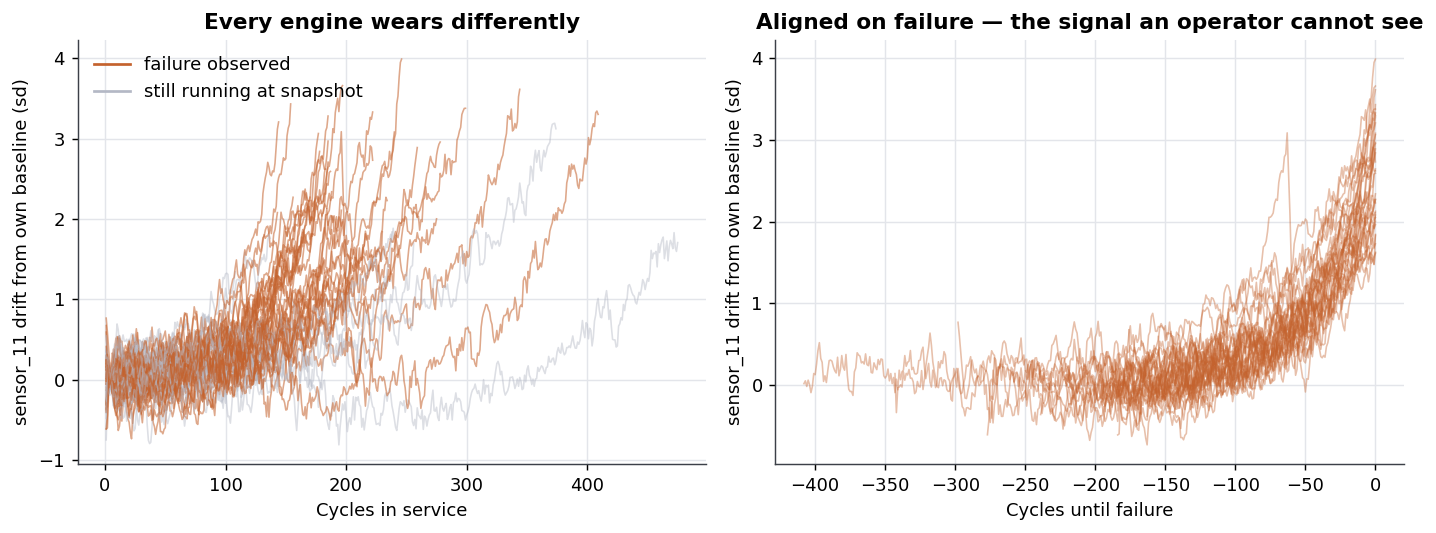

In [7]:
prepared = panel.prepare(trajectories)
risk_set = prepared["risk_set"]
fleet = prepared["fleet"]
features = prepared["feature_columns"]

print(f"regimes            : {prepared['n_regimes']}")
print(f"sensors kept       : {len(prepared['sensors_kept'])}")
print(f"censored fraction  : {prepared['censoring']['realised_rate']:.1%} "
      f"(target {prepared['censoring']['target_rate']:.0%})")
print(f"horizon ceiling U  : {prepared['censoring']['horizon_ceiling']} cycles")
print(f"risk-set rows      : {len(risk_set):,}")

Image(filename=str(figures.degradation_trajectories(risk_set)))

## 4. Method

### 4.1 Removing information on purpose

This is the decision the whole project rests on, so it is worth stating precisely.

Each unit *i* has a true failure cycle `T_i`, known from the raw data and hidden from every
model. It is assigned a snapshot horizon `C_i` drawn uniformly from `{1..U}`,
**independently of `T_i`**. The unit is then observed for `Y_i = min(T_i, C_i)` cycles,
with event indicator `δ_i = 1{T_i ≤ C_i}`.

Three properties this buys, each of which matters:

- **Independent censoring holds by construction.** Kaplan-Meier and the partial likelihood
  both require it; here it is true by design rather than hoped for.
- **It is administrative, not left-truncating.** Each unit is watched from cycle 1, so
  there is no delayed entry to handle at the unit level.
- **It is reproducible.** `U` is *solved for* by bisection to hit a target censored
  fraction, so the censoring rate is a chosen property of the design rather than whatever
  fell out of an arbitrary constant.

Implemented in `panel.induce_censoring` and `panel.calibrate_horizon`.

In [8]:
lifetimes = panel.unit_lifetimes(trajectories)
for target in (0.2, 0.4, 0.6):
    ceiling = panel.calibrate_horizon(lifetimes["true_lifetime"].to_numpy(), target)
    print(f"target {target:.0%} censored -> horizon ceiling U = {ceiling:>4} cycles")

correlation = np.corrcoef(fleet["horizon"], fleet["true_lifetime"])[0, 1]
print(f"\ncorrelation(horizon, true lifetime) = {correlation:+.4f}")
print("Near zero, as it must be: the censoring must not see what it is censoring.")

target 20% censored -> horizon ceiling U = 1126 cycles
target 40% censored -> horizon ceiling U =  563 cycles
target 60% censored -> horizon ceiling U =  372 cycles

correlation(horizon, true lifetime) = +0.0094
Near zero, as it must be: the censoring must not see what it is censoring.


### 4.2 Two panels, and why the separation is load-bearing

- **`risk_set`** — truncated at the snapshot. The **only** thing any model is fitted on.
- **`evaluation_panel`** — the complete run to failure. Used **only** to simulate what a
  policy would have cost.

A maintenance policy has to be scored on what *would have happened*: if the alarm fires at
cycle 190 and the engine would have run to 240, the policy bought 50 cycles of avoided
failure and gave up 50 cycles of service. That counterfactual needs the whole trajectory,
including the part the models are forbidden to see.

Being able to build the second panel at all is the reason a simulator benchmark is worth
using. On a real fleet the counterfactual is unobservable and a policy can only be argued
for, never measured.

### 4.3 Drift, not level

Engines enter service with different, unstated initial wear, so a sensor's *level*
confounds "born worn" with "worn out". The change since the unit's own first few cycles
separates them.

That is a claim about out-of-sample behaviour, so it is tested out of sample rather than
asserted — see section 5.2.

### 4.4 A ladder of models

Each rung exists to justify the next.

log-rank across the four subsets: chi2 = 44.4, df = 3, p = 1.27e-09


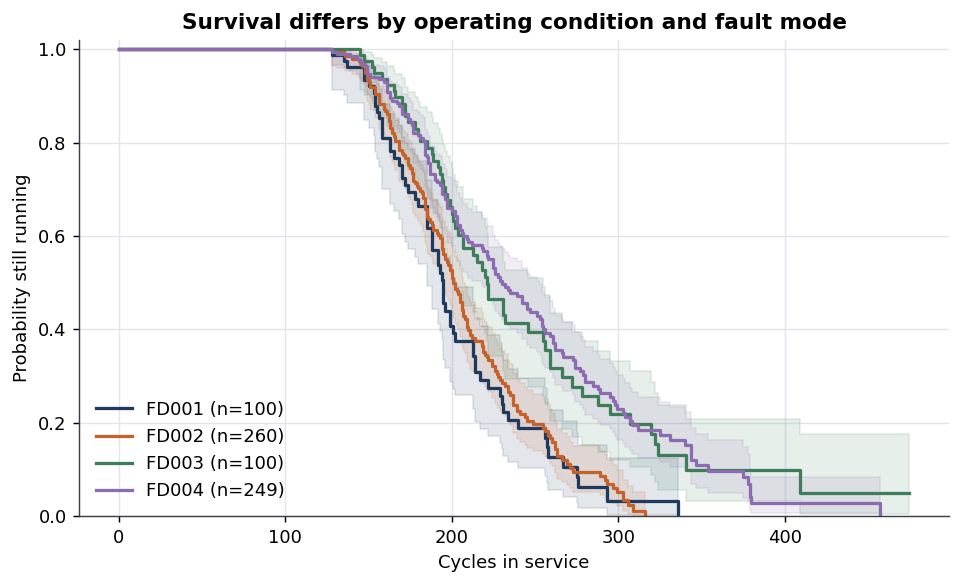

In [9]:
# Rung 1: no covariates, no functional form. Do the fleet designs differ at all?
curves = survival.kaplan_meier(fleet)
logrank = survival.logrank(fleet)
print(f"log-rank across the four subsets: chi2 = {logrank['test_statistic']:.1f}, "
      f"df = {logrank['degrees_of_freedom']}, p = {logrank['p_value']:.2e}")
Image(filename=str(figures.survival_curves(curves)))

They differ, decisively. Only now is it legitimate for a model to condition on subset.

Next, two decisions the data forced.

In [10]:
fit_all = risk_set.loc[risk_set["split"] == "fit"]
window_start = survival.risk_window_start(fit_all)

fit = survival.restrict_to_risk_window(fit_all, window_start)
holdout = survival.restrict_to_risk_window(
    risk_set.loc[risk_set["split"] == "holdout"], window_start
)
edges = survival.derive_band_edges(fit)

print(f"No unit in this fleet fails before cycle {window_start}.")
print(f"  rows below it : {len(fit_all) - len(fit):,}  (constant outcome, zero failures)")
print(f"  engines lost  : {fit_all['unit_id'].nunique() - fit['unit_id'].nunique()}"
      f" of {fit_all['unit_id'].nunique()} (censored before the window opens)")
print(f"\nhazard band edges: {edges.astype(int).tolist()}")

bands = survival.assign_band(fit["cycle"].to_numpy(), edges)
print("failures per band:",
      pd.Series(fit["failed"].to_numpy()).groupby(bands).sum().to_dict())

No unit in this fleet fails before cycle 128.
  rows below it : 56,497  (constant outcome, zero failures)
  engines lost  : 106 of 496 (censored before the window opens)

hazard band edges: [128, 154, 167, 177, 188, 197, 208, 229, 257, 295]
failures per band: {1: 29, 2: 30, 3: 26, 4: 33, 5: 27, 6: 33, 7: 30, 8: 30, 9: 29, 10: 31}


**Two things just happened, and both are modelling decisions rather than housekeeping.**

**Left truncation at cycle 128.** Those ~40,000 early rows have a *constant* outcome — no
failure ever occurs there — so a logistic model asked to explain them drives its intercept
to minus infinity. That is textbook complete separation: the fit does not converge and the
Hessian is singular. Restricting the risk set is the honest response, and it has a name:
the hazard is estimated **conditional on surviving to cycle 128**. The model says nothing
about the first 127 cycles, and it should not — there is no failure there to learn from.
The price is 106 engines censored before the window opens, which drop out entirely.

**Equal-event hazard bands.** Equal-*width* bands fail in the sparse tail, where several
20-cycle bands hold a few dozen rows and no failures at all — again a minus-infinity
coefficient. Cutting at the quantiles of observed failure cycles gives every band roughly
thirty events and none empty. The edges are derived from the **fit set only**; quantiles of
holdout failure times would be the holdout's answers leaking into the design matrix.

In [11]:
# Rung 2: Cox proportional hazards, fitted so its assumption can be tested.
cox = survival.fit_cox_time_varying(fit, features)
ph = survival.test_proportional_hazards(cox, fit, features)

print(f"Proportional hazards violated by {int(ph['violates_ph'].sum())} of {len(features)} "
      f"covariates (Holm-corrected for multiple testing)\n")
ph.head(8).round(4)

Proportional hazards violated by 10 of 17 covariates (Holm-corrected for multiple testing)



,covariate,correlation,p_value,coefficient,p_holm,violates_ph
0,sensor_4_drift,-0.3364,0.0000,0.1496,0.0000,True
1,sensor_11_drift,-0.2710,0.0000,0.1451,0.0000,True
2,sensor_2_drift,-0.2462,0.0000,0.1300,0.0002,True
3,sensor_3_drift,-0.2444,0.0000,0.1387,0.0003,True
4,sensor_10_drift,-0.2277,0.0001,0.0142,0.0009,True
5,sensor_12_drift,-0.2121,0.0002,-0.0042,0.0026,True
6,sensor_7_drift,-0.1762,0.0022,-0.0051,0.0245,True
7,sensor_14_drift,0.1733,0.0026,0.0240,0.0264,True


Cox's central assumption — that a covariate's effect on the log-hazard is the same at cycle
130 as at cycle 350 — **fails on 10 of 17 covariates**. Worse for Cox, the violations are
concentrated in the *highest-effect* sensors (4, 11, 2, 3, 17): their influence weakens as
a unit ages.

A note on how that was tested, because the obvious version of the test is wrong here. The
shortcut — correlate raw covariate values at failures with failure time — tests something
else entirely: the drift features **rise with age by construction**, so it flags
essentially every covariate whether or not the model's assumption is broken.
`survival.schoenfeld_residuals` subtracts the model's own expectation at each failure time,
which is exactly what removes that artefact.

So the workhorse is the discrete-time model, for three reasons in order of weight:

1. **The decision needs an absolute probability, not a ranking.** Cox's partial likelihood
   deliberately factors the baseline hazard out. "Pull when 30-cycle risk exceeds *p*" is a
   statement about an absolute probability.
2. **Time is discrete.** One inspection per cycle, fail or not — a Bernoulli trial per
   cycle at risk, which is what a logistic regression on the risk set estimates. Cox assumes
   continuous time in which exact ties cannot occur; here ties *are* the data.
3. **Duration dependence is the question**, and PH has just been shown to fail.

In [12]:
# Rung 3: the workhorse. Standard errors clustered by unit - one engine contributes
# hundreds of correlated rows, and treating them as independent would shrink the
# standard errors by roughly sqrt(average unit length).
hazard = survival.fit_discrete_hazard(fit, features, edges)
coefficients = survival.tidy(hazard)

print(f"parameters : {len(hazard.params)}")
print(f"events     : {int(fit['failed'].sum())} over {len(fit):,} unit-cycles at risk")
print(f"converged  : {hazard.mle_retvals['converged']}")
print(f"pseudo-R2  : {hazard.prsquared:.3f}\n")

sensor_terms = coefficients[~coefficients["term"].str.startswith(("band_", "const"))]
sensor_terms.sort_values("p_value").head(6).round(4)

parameters : 27


events     : 298 over 32,587 unit-cycles at risk
converged  : True
pseudo-R2  : 0.397



,term,coefficient,std_error,p_value,odds_ratio,or_lower,or_upper
9,sensor_11_drift,1.2287,0.2351,0.0000,3.4169,2.1555,5.4164
15,sensor_17_drift,0.7426,0.1775,0.0000,2.1013,1.4839,2.9756
2,sensor_3_drift,0.5445,0.1448,0.0002,1.7238,1.2979,2.2894
3,sensor_4_drift,0.7622,0.2088,0.0003,2.1431,1.4232,3.2270
14,sensor_16_drift,0.5040,0.2211,0.0227,1.6553,1.0731,2.5533
10,sensor_12_drift,-0.5741,0.2934,0.0504,0.5632,0.3169,1.0010


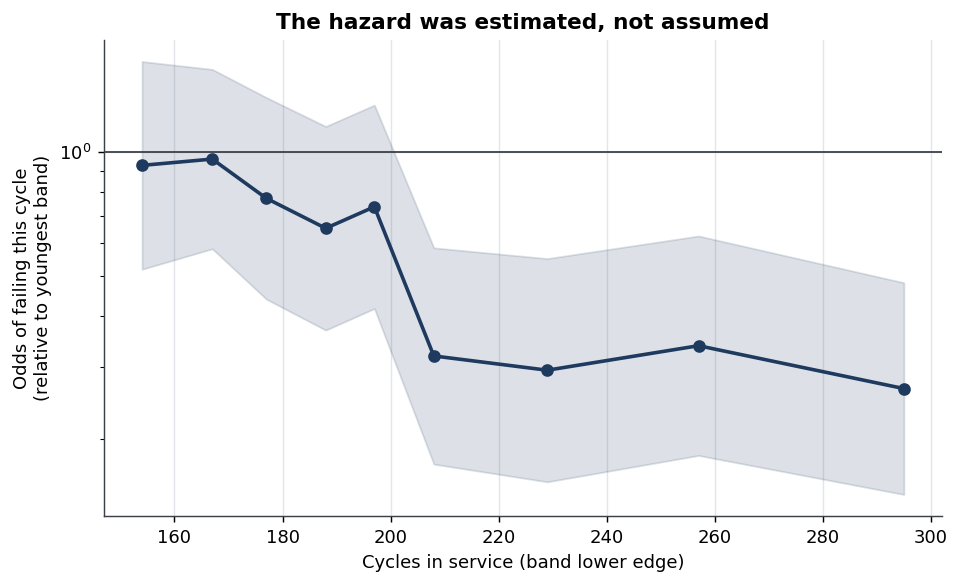

In [13]:
Image(filename=str(figures.baseline_hazard(coefficients, edges)))

The baseline hazard was **estimated, not assumed** — that is the whole reason cycle enters
as band dummies rather than as a linear term. Whether risk accelerates with age is the
question a maintenance policy turns on, so imposing the answer would have been circular.

## 5. Results

### 5.1 What ignoring censoring costs

The measurement the project is built around. Three estimates of the same quantity, against
a truth that is actually known.

In [14]:
bias = evaluate.censoring_bias(fleet)

comparison = pd.DataFrame([
    {"estimate": "Truth (full trajectories)", "mean life": bias["true_mean_life"],
     "error": 0.0, "error %": 0.0},
    {"estimate": "Complete-case (drop unfailed)", "mean life": bias["complete_case_mean_life"],
     "error": bias["complete_case_bias_cycles"], "error %": bias["complete_case_bias_pct"]},
    {"estimate": "Naive (snapshot as lifetime)", "mean life": bias["naive_observed_mean_life"],
     "error": bias["naive_bias_cycles"],
     "error %": 100 * bias["naive_bias_cycles"] / bias["true_mean_life"]},
]).round(2)
display(comparison)

print(f"\nKaplan-Meier median {bias['kaplan_meier_median']:.0f} vs "
      f"true median {bias['true_median_life']:.0f} cycles "
      f"-> error {bias['kaplan_meier_median_error']:+.0f}")

,estimate,mean life,error,error %
0,Truth (full trajectories),226.18,0.00,0.00
1,Complete-case (drop unfailed),211.94,-14.24,-6.30
2,Naive (snapshot as lifetime),178.98,-47.19,-20.87



Kaplan-Meier median 209 vs true median 207 cycles -> error +2


The direction is not an accident and it is worth being able to say out loud: **a unit is
censored exactly when its lifetime exceeds its horizon**, so deleting censored units
deletes the long-lived ones preferentially. The surviving sample is biased short and the
fleet looks more fragile than it is.

A single censoring rate could always be dismissed as contrived, so it is swept.

,target_censor_rate,realised_censor_rate,complete_case_bias_cycles,complete_case_bias_pct,kaplan_meier_median_error,events
0,0.2,0.19,-3.54,-1.57,0.0,573
1,0.3,0.28,-6.49,-2.87,0.0,509
2,0.4,0.40,-14.24,-6.30,2.0,423
3,0.5,0.50,-19.04,-8.42,2.0,354
4,0.6,0.58,-25.94,-11.47,0.0,295
5,0.7,0.68,-33.04,-14.61,1.0,227


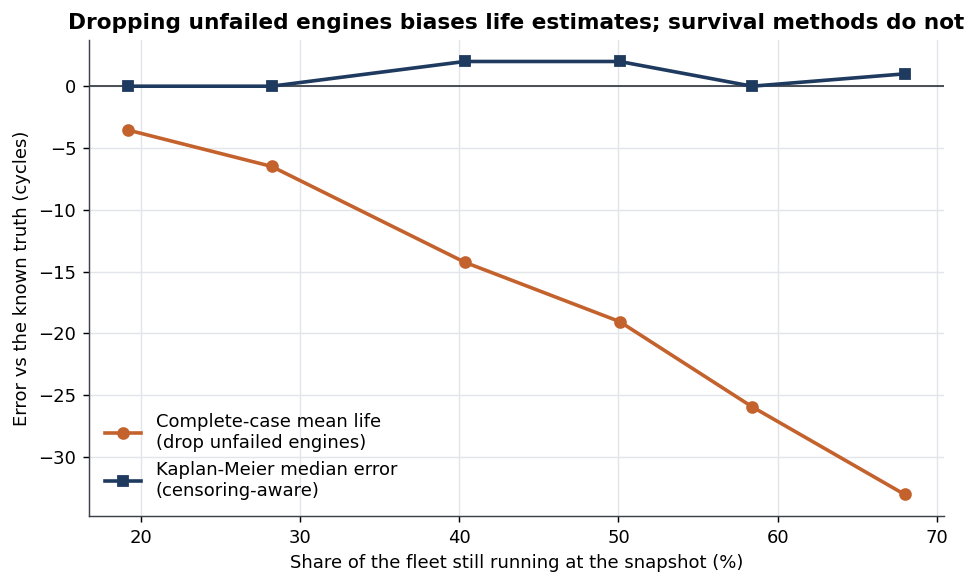

In [15]:
bias_sweep = evaluate.bias_by_censoring_rate(trajectories)
display(bias_sweep.round(2))
Image(filename=str(figures.censoring_bias(bias_sweep)))

The bias grows monotonically with how much of the fleet is still running — which is the
direction that matters, because real fleets are mostly survivors.

The second series is the positive half of the argument, and it is why this project has a
recommendation rather than just a complaint: **the information is not destroyed by
censoring, only by the wrong estimator.** Kaplan-Meier's error stays on zero throughout.

### 5.2 Testing the "drift, not level" claim

In [16]:
feature_comparison = evaluate.compare_feature_sets(
    fit, holdout, features, prepared["level_columns"], edges, landmarks=(150, 175, 200)
)
feature_comparison.round(4)

,feature_set,n_parameters,in_sample_pseudo_r2,holdout_harrell_c,holdout_uno_c
0,drift,27,0.3967,0.8955,0.8814
1,level,27,0.5899,0.8541,0.8312
2,drift + level,44,0.5990,0.8597,0.8362


The level features fit **much** better in sample (pseudo-R² 0.59 vs 0.40) and discriminate
**worse** out of it (Uno's C 0.83 vs 0.88). That is what overfitting looks like, and it is
why the model uses drift alone. The a-priori argument was right, but it is reported as a
measurement rather than an assertion.

### 5.3 Does it discriminate?

Scoring is done at **landmarks**: fix a cycle, keep the units still running, use their
readings at that instant, and score how well predicted risk orders what happens next. A
time-varying-covariate model does not have one C-index; it has one per moment at which you
might ask.

In [17]:
scores = evaluate.landmark_scores(hazard, holdout, features, edges, fit,
                                  landmarks=(150, 175, 200))
display(scores.round(4))

brier = evaluate.brier(hazard, holdout, features, edges, fit, 150)
print(f"\nintegrated Brier score      : {brier['integrated_brier_score']:.4f}")
print(f"Kaplan-Meier baseline       : {brier['baseline_integrated_brier_score']:.4f}")
print(f"improvement                 : {brier['improvement']:.4f}")

,landmark,units_at_risk,events,harrell_c,uno_c,mean_predicted_risk
0,150,153,120,0.8832,0.8640,0.0760
1,175,119,96,0.8990,0.8886,0.0818
2,200,88,69,0.9042,0.8917,0.1707



integrated Brier score      : 0.1219
Kaplan-Meier baseline       : 0.1584
improvement                 : 0.0365


Both concordance indices are reported deliberately. **Harrell's C** is biased under
censoring — the comparable pairs it can form are not a random sample. **Uno's C**
reweights by the inverse probability of remaining uncensored and is not. In a project whose
subject is censoring, quoting only the censoring-sensitive metric would be self-defeating.

The Brier comparison is the reference every prognostic model should have to clear: the
fleet-wide Kaplan-Meier curve uses no sensor information at all. Beating it is evidence
the sensors are being read to some effect.

### 5.4 The weakness, measured rather than mentioned

,bin,units,mean_predicted,observed_km
0,0,16,0.0005,0.0000
1,1,15,0.0009,0.0000
2,2,15,0.0016,0.0000
3,3,15,0.0027,0.0000
4,4,16,0.0041,0.0000
5,5,15,0.0065,0.0000
6,6,15,0.0112,0.0000
7,7,15,0.0220,0.2103
8,8,15,0.0597,0.4667
9,9,16,0.6239,1.0000


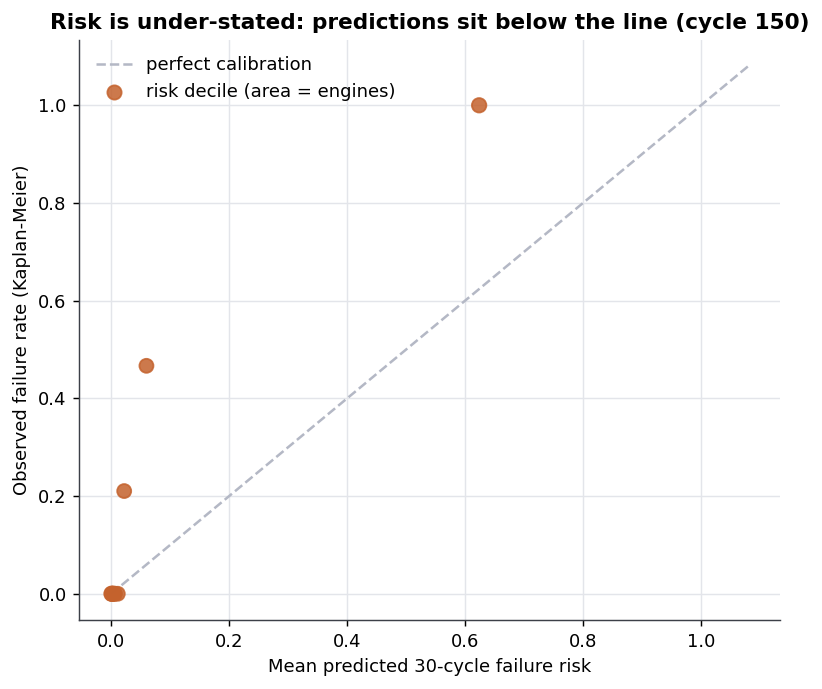

In [18]:
calibration = evaluate.calibration(hazard, holdout, features, edges, 150)
display(calibration.round(4))
Image(filename=str(figures.calibration(calibration, 150)))

**The model is badly under-confident in the top deciles** — it predicts 62% where the
observed rate is 100%. The mechanism is known and is a direct consequence of a design
choice: `survival.horizon_risk` compounds the per-cycle hazard forward while **freezing
the sensor readings at their current value**, so a unit degrading unusually fast has its
future understated.

That freezing is not laziness. At the moment of the decision, today's readings are all the
operator has; a model that needed tomorrow's would be unusable. But it has a consequence
for the decision layer, and section 6 is built around it rather than around hoping it does
not matter.

## 6. The decision

### 6.1 The cost metric, and the trap in the obvious one

Score a policy on cost **per unit** and the optimum is degenerate: pull every machine on
cycle 1, nothing ever fails, every removal is the cheap kind, and the fleet does no work.

The metric has to charge for the service given up:

$$\text{cost per 1,000 cycles} = \frac{1000 \times \sum_i \text{cost}_i}{\sum_i \text{cycles delivered}_i}$$

Pulling early buys a lower numerator at the price of a smaller denominator. That is the
real trade, and it cannot be gamed by being conservative.

### 6.2 Why the threshold is swept, not calculated

For a **calibrated** model the answer is analytic: act when risk exceeds `c_pull / c_fail`.
Section 5.4 showed this model is not calibrated, so that formula fires too late.

Two responses were available. Recalibrate — but the outcome needed to fit a recalibration
is itself censored, which repairs one bias by introducing another. Or stop relying on the
probabilities being right: **sweep** the threshold and pick the one that actually costs
least. That makes the threshold a *rank* cut, and the model only has to order units
correctly — which it does, at Uno's C ≈ 0.88.

The gap between the two is measured below rather than left as a caveat.

In [19]:
evaluation_panel = prepared["evaluation_panel"]
paths = policy.score_paths(
    hazard, evaluation_panel.loc[evaluation_panel["split"] == "holdout"],
    features, edges, window_start
)

comparison = policy.compare_policies(paths)
bootstrap = policy.bootstrap_optimum(paths)

model, interval = comparison["model"], comparison["fixed_interval"]
table = pd.DataFrame([
    {"policy": "Run to failure",
     "cost per 1,000 cycles": comparison["run_to_failure"]["cost_per_1000_cycles"],
     "failure rate": comparison["run_to_failure"]["failure_rate"],
     "service per unit": comparison["run_to_failure"]["mean_service_cycles"]},
    {"policy": f"Best fixed interval ({interval['interval']:.0f} cycles)",
     "cost per 1,000 cycles": interval["cost_per_1000_cycles"],
     "failure rate": interval["failure_rate"],
     "service per unit": interval["mean_service_cycles"]},
    {"policy": f"Model policy (threshold {model['threshold']:.3f})",
     "cost per 1,000 cycles": model["cost_per_1000_cycles"],
     "failure rate": model["failure_rate"],
     "service per unit": model["mean_service_cycles"]},
]).round(3)
display(table)

print(f"\nSaving vs best fixed interval: {comparison['saving_vs_fixed_interval_pct']:.1f}% "
      f"(95% CI {bootstrap['saving_vs_interval_ci'][0]:.1f}-"
      f"{bootstrap['saving_vs_interval_ci'][1]:.1f}%)")
print(f"Optimal threshold: {model['threshold']:.3f} "
      f"(95% CI {bootstrap['threshold_ci'][0]:.3f}-{bootstrap['threshold_ci'][1]:.3f})")

,policy,"cost per 1,000 cycles",failure rate,service per unit
0,Run to failure,21.866,1.000,228.662
1,Best fixed interval (140 cycles),7.417,0.009,139.887
2,Model policy (threshold 0.077),5.085,0.009,204.023



Saving vs best fixed interval: 31.4% (95% CI 28.0-34.3%)
Optimal threshold: 0.077 (95% CI 0.077-0.102)


**The headline, in the clearest form available:** the calendar policy and the model policy
accept **the same 0.9% failure rate**. The calendar gets there by pulling every unit at 140
cycles. The model gets there by pulling each unit when *that unit* looks unwell — at 204
cycles on average. Same safety, 46% more working life.

The baseline is the *best* fixed interval, swept across the whole grid, not a strawman. A
condition-based policy that could not beat a well-chosen calendar would not be worth the
sensors.

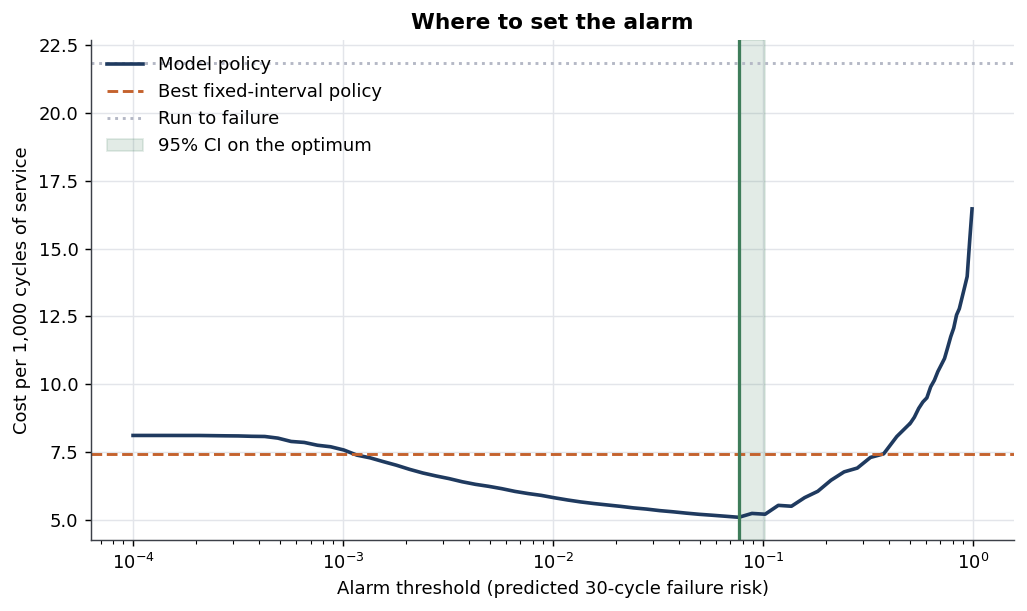

In [20]:
Image(filename=str(figures.threshold_sweep(
    comparison["model_sweep"], model, bootstrap,
    interval["cost_per_1000_cycles"],
    comparison["run_to_failure"]["cost_per_1000_cycles"])))

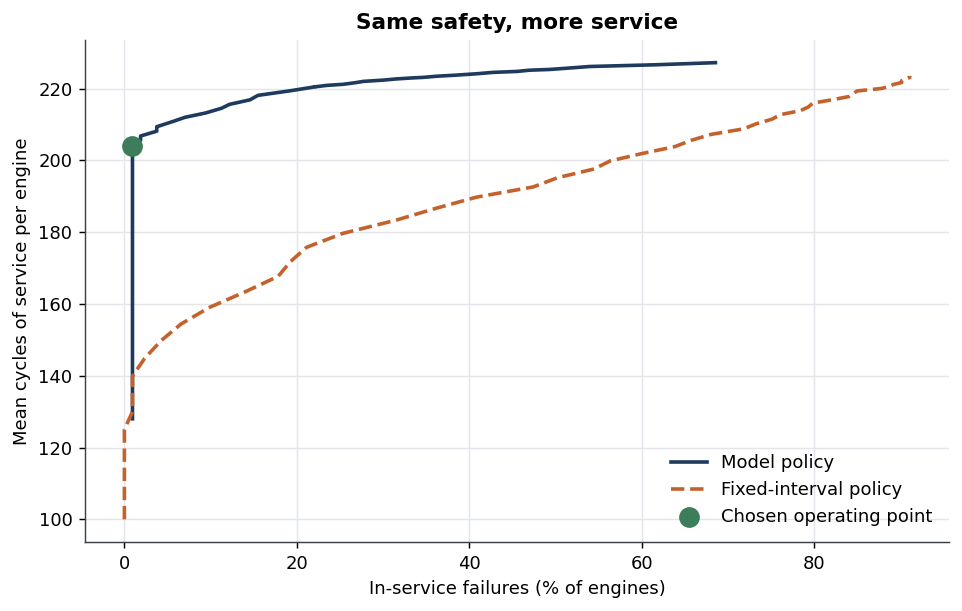

In [21]:
Image(filename=str(figures.policy_frontier(comparison["model_sweep"], comparison["interval_sweep"], model)))

### 6.3 What trusting the uncalibrated probability would have cost

In [22]:
analytic = policy.analytic_threshold_penalty(paths)
pd.DataFrame([
    {"threshold rule": "Textbook (c_pull / c_fail)", "threshold": analytic["analytic_threshold"],
     "cost per 1,000": analytic["analytic_cost"], "failure rate": analytic["analytic_failure_rate"]},
    {"threshold rule": "Swept (chosen by measured cost)", "threshold": analytic["empirical_threshold"],
     "cost per 1,000": analytic["empirical_cost"], "failure rate": analytic["empirical_failure_rate"]},
]).round(4)

,threshold rule,threshold,"cost per 1,000",failure rate
0,Textbook (c_pull / c_fail),0.2000,6.1987,0.0798
1,Swept (chosen by measured cost),0.0767,5.0855,0.0094


The textbook rule costs **21.9% more** and accepts an **8.0% failure rate instead of
0.9%** — an eightfold increase in in-service failures. That is the difference between
naming a limitation and measuring one.

### 6.4 Is it operationally usable?

A policy with a superb cost curve and a two-cycle lead time cannot be acted on — you cannot
get a shop slot, a part and a crew inside two flights. The distribution matters more than
the mean, because the left tail is the operational risk.

engines pulled in time : 211 of 213
median lead time       : 25 cycles
10th percentile        : 12 cycles
minimum                : 1 cycles


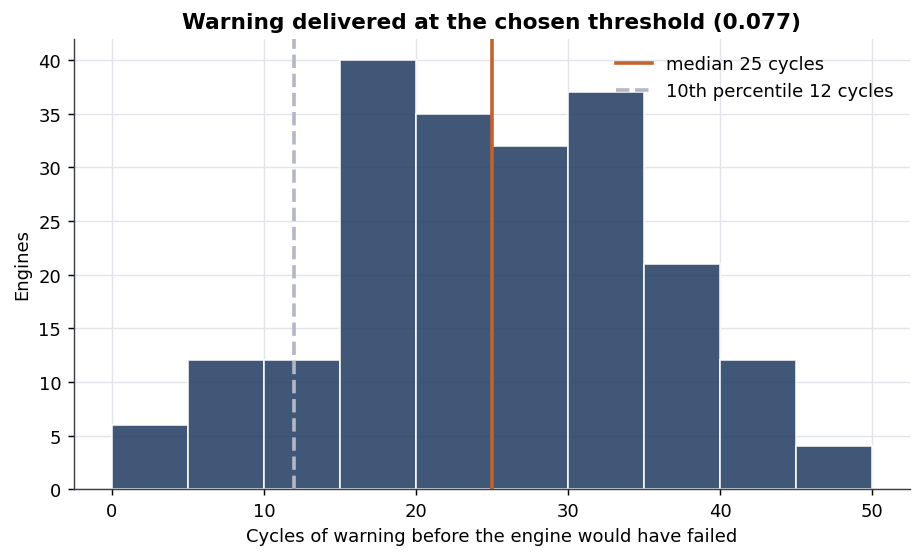

In [23]:
leads = policy.lead_time_distribution(paths, model["threshold"])
pulled = leads.loc[leads["pulled"], "lead_time"]
print(f"engines pulled in time : {int(leads['pulled'].sum())} of {len(leads)}")
print(f"median lead time       : {pulled.median():.0f} cycles")
print(f"10th percentile        : {np.percentile(pulled, 10):.0f} cycles")
print(f"minimum                : {pulled.min():.0f} cycles")

Image(filename=str(figures.lead_times(leads, model["threshold"])))

### 6.5 The one input this analysis does not know

The ratio of failure cost to planned-removal cost varies by fleet and by contract, and a
maintenance organisation knows it better than this analysis does. Reporting a single optimum
for one assumed ratio would hand over a number that quietly depends on a guess. Reporting
the curve hands over something usable.

,cost_ratio,optimal_threshold,model_cost,model_failure_rate,model_mean_lead_time,best_interval,interval_cost,run_to_failure_cost,saving_vs_interval_pct
0,2.0,0.102,4.927,0.019,22.297,180.0,6.891,8.747,28.503
1,3.0,0.077,4.993,0.009,24.872,145.0,7.228,13.120,30.918
2,5.0,0.077,5.085,0.009,24.872,140.0,7.417,21.866,31.436
3,8.0,0.077,5.224,0.009,24.872,140.0,7.618,34.986,31.436
4,12.0,0.077,5.408,0.009,24.872,140.0,7.887,52.479,31.436
5,20.0,0.077,5.776,0.009,24.872,125.0,8.000,87.465,27.802


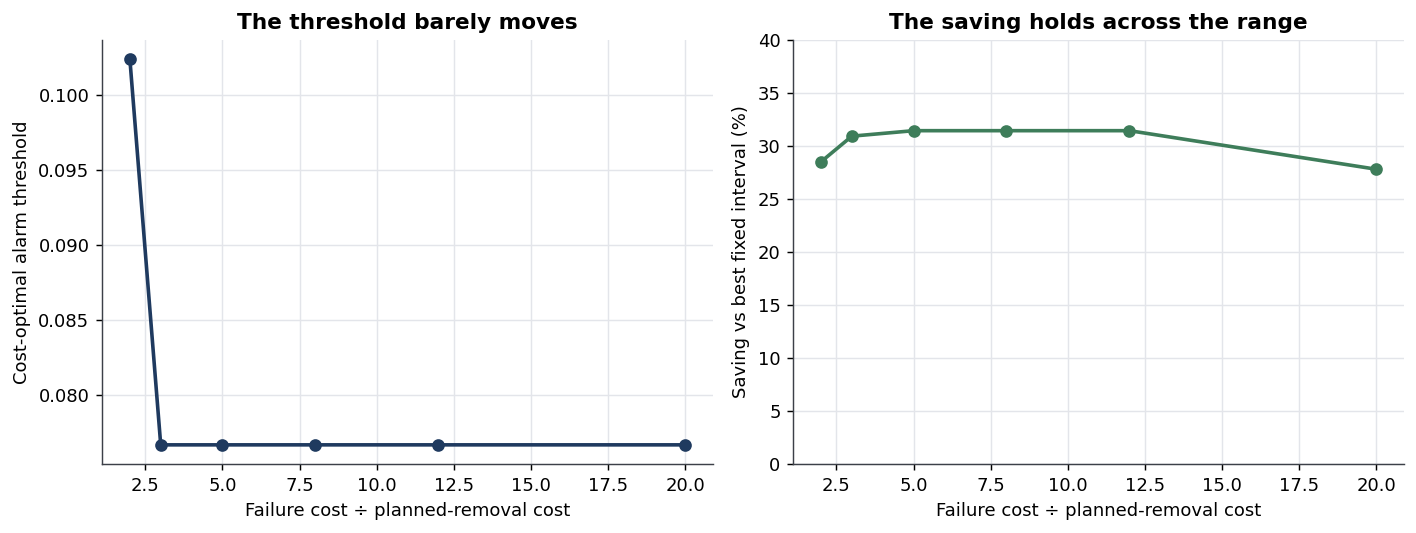

In [24]:
sensitivity = policy.cost_ratio_sensitivity(paths)
display(sensitivity.round(3))
Image(filename=str(figures.cost_ratio_sensitivity(sensitivity)))

Across a ten-fold range of cost ratios the saving stays between 28% and 31%, and the
recommended threshold barely moves. The recommendation does not depend on getting the cost
ratio right.

## 7. Limitations

- **The data is simulated.** C-MAPSS is physics-model output with injected noise, not
  measurements from a real fleet. Nothing here is a claim about real turbofans. The
  *methods* transfer; the specific numbers do not.
- **Censoring is induced by design, not observed.** The mechanism is administrative and
  independent of lifetime by construction. Real maintenance data often has **informative**
  censoring — units pulled *because* they looked unwell — which breaks both Kaplan-Meier
  and the partial likelihood. That case is out of scope here and would need a different
  approach: either a joint model of the pull decision and the failure process, or an
  instrument for why a unit was pulled.
- **The model is not well calibrated.** It understates risk in the top deciles, for the
  reason given in 5.4. The decision layer is designed around this rather than pretending
  otherwise, and the cost of ignoring it is quantified at 21.9%.
- **Forward risk freezes the covariates.** A unit degrading unusually fast has its future
  understated, which makes the reported policy gain conservative rather than flattering.
- **Costs are relative, not currency.** A planned removal is 1 and a failure is the
  multiple; no monetary figure is claimed. The sensitivity sweep is what makes the
  recommendation usable without one.
- **The analysis says nothing before cycle 128**, by construction, and 106 fit-set units
  censored before that window drop out of the model fit entirely.

## 8. What I would do about it

**Set the alarm at a predicted 30-cycle failure risk of 0.077**, having first read the
threshold off the sensitivity curve in 6.5 using the organisation's own failure-to-removal
cost ratio. Expect roughly a 31% reduction in cost per cycle of service against a
well-tuned calendar schedule, at the same in-service failure rate, with a median 25 cycles
of warning and a 10th percentile of 12.

**Two conditions on that recommendation**, both of which are checkable before anything is
deployed:

1. **Do not read the probabilities as probabilities.** The threshold is a rank cut chosen
   by measured cost. If someone wants a calibrated risk number for a different purpose, the
   model needs recalibrating first, and doing that properly on censored outcomes is its own
   piece of work.
2. **Verify that pulls are not already condition-driven.** The entire analysis assumes
   censoring is independent of health. In an organisation where units are already pulled
   because they looked unwell, that assumption is false and these estimates are an upper
   bound on how well this works.

**The transferable finding**, which outlives the specific numbers: if you are modelling
time to failure and your method needs a completed lifetime as its target, you are training
on a biased sample of your fleet — and the bias grows with the share of machines still
running, which is to say with how normal your fleet is.

## 9. Reproducing this

From a clean checkout:

```bash
py -3.10 -m venv .venv && .venv/Scripts/pip install -r requirements.txt
python src/acquisition.py
python -m pytest -q
python run_analysis.py
```

`run_analysis.py` regenerates every number in this notebook and in the README, plus all ten
figures, in about 20 seconds. This notebook imports `src/` and calls the same functions the
script does — it never re-implements an analysis path, which is the only way to guarantee
the notebook and the script cannot disagree.

49 tests pin the claims, including a seeded-reproducibility check on the censoring
mechanism and a cost-sweep optimum verified against a fixture whose answer is a calculation
rather than a re-run of the code being tested.

**Data:** Saxena, A. and Goebel, K. (2008). *Turbofan Engine Degradation Simulation Data
Set*. NASA Prognostics Data Repository, NASA Ames Research Center. Work of the U.S.
Government — public domain.

In [25]:
print("Figures written to outputs/figures/:")
for path in sorted(figures.FIGURE_DIR.glob("*.png")):
    print(f"  {path.name}")

Figures written to outputs/figures/:
  01_degradation_trajectories.png
  02_survival_by_subset.png
  03_censoring_bias.png
  04_baseline_hazard.png
  05_calibration.png
  06_threshold_sweep.png
  07_policy_frontier.png
  08_lead_times.png
  09_cost_ratio_sensitivity.png
  10_time_dependent_auc.png
